# 03 — Frozen evaluation, results and interpretation

Prerequisite: notebook 02 completed all fits and froze validation-only selection. This notebook reloads the newly trained artifacts and computes test results once. **It does not compare repeated executions as separate treatments.**

Primary contrast: league MLP minus Arsenal-only MLP log loss on identical Arsenal test fixtures. Secondary metrics: multiclass Brier sum (0–2), accuracy and calibration. Test results have been inspected historically, so this remains a reproducibility rerun.

In [1]:
from pathlib import Path
import sys, json
PROJECT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/study.py').exists())
sys.path.insert(0,str(PROJECT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from experiments import study, train
DATA=study.DATA; RUN=study.RUN
plt.rcParams.update({'font.size':11,'figure.figsize':(11,5),'axes.spines.top':False,'axes.spines.right':False})
BLUE='#236B8E'; GOLD='#B78126'; GREY='#737373'
def finish(name):
    plt.tight_layout()
    plt.savefig(RUN/'figures'/f'{name}.png',dpi=150,bbox_inches='tight')
    plt.show()

metrics,comparison,diagnostics=study.evaluate()
test=metrics.query("split=='test' and population=='Arsenal'")
display(test[['model','n','log_loss','brier_multiclass','accuracy']].round(6))
display(pd.Series(comparison))
display(pd.Series(diagnostics))

,model,n,log_loss,brier_multiclass,accuracy
18,arsenal_mlp,75,0.959723,0.569044,0.600000
21,league_mlp,75,0.899941,0.529087,0.613333
24,league_to_arsenal_mlp,75,0.900410,0.529357,0.613333
27,league_logistic,75,0.908957,0.532644,0.613333
30,arsenal_logistic,75,0.909300,0.534445,0.640000
33,league_prior,75,1.094381,0.664183,0.400000


contrast                        League minus Arsenal-only MLP test log loss
difference                                                        -0.059782
interval_95_percentile        [-0.10078658796846866, -0.016193701140582585]
blocks                                                                   20
resamples                                                              1000
limitation                Same inspected test period; interval excludes ...
dtype: object

max_difference_between_independent_models              0.25423
independent_models_are_not_identical                      True
max_probability_change_when_feature_rows_reordered    0.690193
dtype: object

## 1. One fresh result set: controls and treatments
The figure compares trained arms within this execution. It does not show three copies of deterministic rerun scores. Loss is primary; accuracy is secondary. Candidate selection remains based on validation.

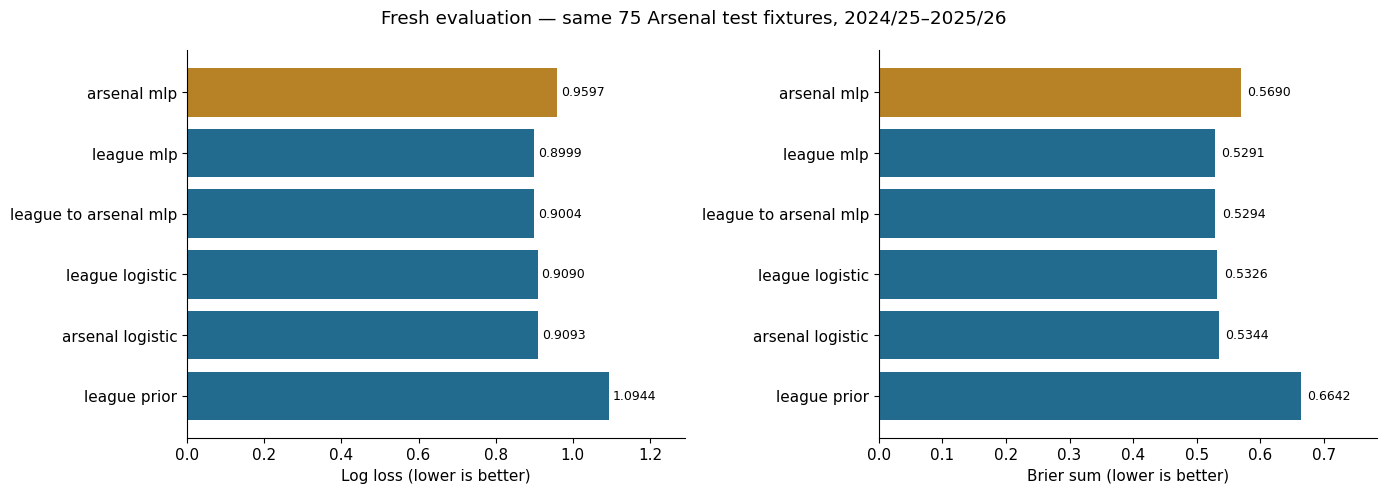

In [2]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,metric,label in [(axes[0],'log_loss','Log loss (lower is better)'),(axes[1],'brier_multiclass','Brier sum (lower is better)')]:
    bars=ax.barh(test.model.str.replace('_',' '),test[metric],color=[GOLD if n=='arsenal_mlp' else BLUE for n in test.model]);ax.invert_yaxis()
    for bar,value in zip(bars,test[metric]):ax.text(value+.01,bar.get_y()+bar.get_height()/2,f'{value:.4f}',va='center',fontsize=9)
    ax.set(xlabel=label,xlim=(0,test[metric].max()*1.18))
fig.suptitle('Fresh evaluation — same 75 Arsenal test fixtures, 2024/25–2025/26');finish('12_test_metrics')

## 2. Paired uncertainty
The month-block bootstrap preserves within-month grouping, uses 1,000 resamples and reports a 95% percentile interval. It measures test-sample variability, not variation across training seeds or new untouched periods. A negative difference favors the league MLP.

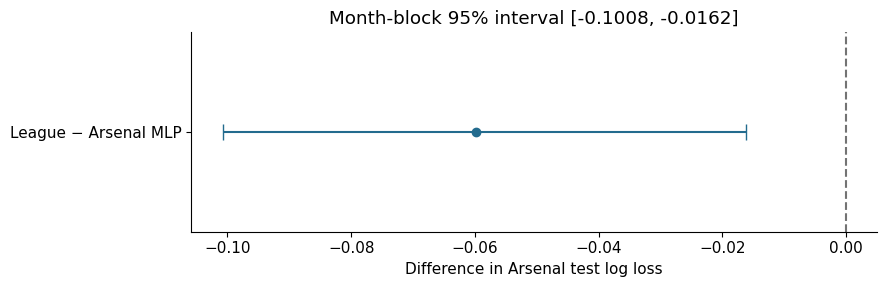

In [3]:
lo,hi=comparison['interval_95_percentile'];delta=comparison['difference']
fig,ax=plt.subplots(figsize=(9,3));ax.errorbar(delta,0,xerr=[[delta-lo],[hi-delta]],fmt='o',color=BLUE,capsize=6);ax.axvline(0,color=GREY,linestyle='--')
ax.set(yticks=[0],yticklabels=['League − Arsenal MLP'],xlabel='Difference in Arsenal test log loss',title=f'Month-block 95% interval [{lo:.4f}, {hi:.4f}]');finish('13_paired_uncertainty')

## 3. Calibration and outcome mistakes
Reliability bins are fixed at five intervals. Bin counts are shown in the table; 75 test fixtures make calibration estimates unstable. A confusion matrix uses the validation-selected candidate, with labels reoriented to Arsenal loss/draw/win.

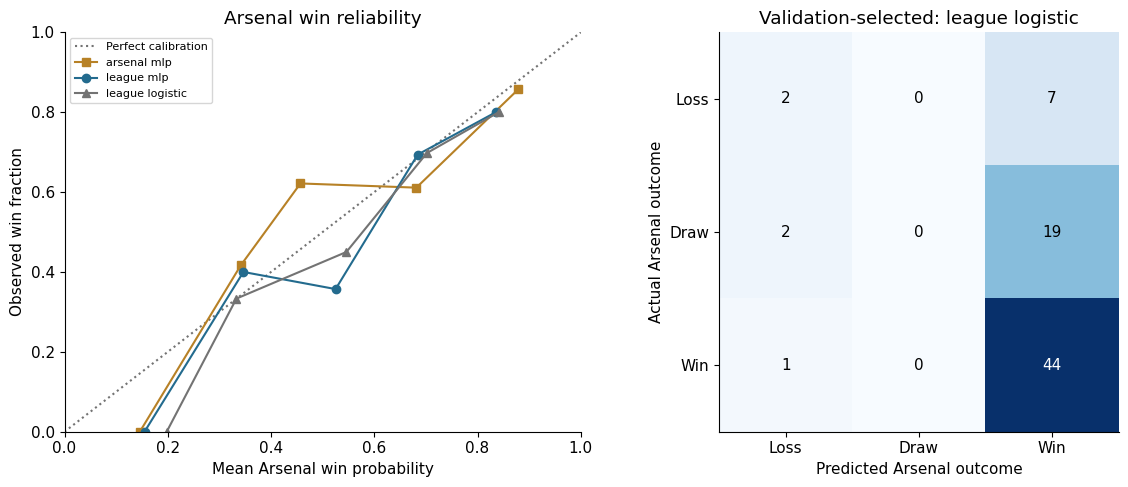

,bin,mean_prediction,observed_rate,count,model
0,"(-0.001, 0.2]",0.145856,0.000000,1,arsenal_mlp
1,"(0.2, 0.4]",0.341423,0.416667,12,arsenal_mlp
2,"(0.4, 0.6]",0.456946,0.621622,37,arsenal_mlp
3,"(0.6, 0.8]",0.681515,0.611111,18,arsenal_mlp
4,"(0.8, 1.0]",0.878839,0.857143,7,arsenal_mlp
5,"(-0.001, 0.2]",0.154953,0.000000,2,league_mlp
6,"(0.2, 0.4]",0.346478,0.400000,5,league_mlp
7,"(0.4, 0.6]",0.525061,0.357143,14,league_mlp
8,"(0.6, 0.8]",0.684146,0.693878,49,league_mlp
9,"(0.8, 1.0]",0.835572,0.800000,5,league_mlp


In [4]:
selection=json.loads((study.MODELS/'selected_model.json').read_text());selected=selection['selected_model']
fig,axes=plt.subplots(1,2,figsize=(12,5));axes[0].plot([0,1],[0,1],':',color=GREY,label='Perfect calibration')
calibration=[]
for name,color,marker in [('arsenal_mlp',GOLD,'s'),('league_mlp',BLUE,'o'),(selected,GREY,'^')]:
    p=pd.read_csv(RUN/'evaluation'/f'{name}_test_arsenal_probabilities.csv')
    p['win']=((p.home_team.eq('Arsenal')&p.target_class.eq('H'))|(p.away_team.eq('Arsenal')&p.target_class.eq('A'))).astype(int)
    p['bin']=pd.cut(p.p_win,np.linspace(0,1,6),include_lowest=True)
    grouped=p.groupby('bin',observed=True).agg(mean_prediction=('p_win','mean'),observed_rate=('win','mean'),count=('win','size'))
    axes[0].plot(grouped.mean_prediction,grouped.observed_rate,marker=marker,color=color,label=name.replace('_',' '));calibration.append(grouped.reset_index().assign(model=name))
axes[0].set(xlim=(0,1),ylim=(0,1),xlabel='Mean Arsenal win probability',ylabel='Observed win fraction',title='Arsenal win reliability');axes[0].legend(fontsize=8)
p=pd.read_csv(RUN/'evaluation'/f'{selected}_test_arsenal_probabilities.csv')
home=p.home_team.eq('Arsenal');actual=np.where(p.target_class.eq('D'),1,np.where((home&p.target_class.eq('H'))|(~home&p.target_class.eq('A')),2,0))
predicted=p[['p_loss','p_draw','p_win']].to_numpy().argmax(1)
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(actual,predicted,labels=[0,1,2]);axes[1].imshow(cm,cmap='Blues')
for i in range(3):
    for j in range(3):axes[1].text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
axes[1].set(xticks=range(3),yticks=range(3),xticklabels=['Loss','Draw','Win'],yticklabels=['Loss','Draw','Win'],xlabel='Predicted Arsenal outcome',ylabel='Actual Arsenal outcome',title='Validation-selected: '+selected.replace('_',' '));finish('14_calibration_confusion')
calibration=pd.concat(calibration,ignore_index=True);calibration.to_csv(RUN/'evaluation/calibration_bins.csv',index=False);display(calibration)

## 4. Temporal/population transfer and per-fixture probabilities
Non-Arsenal test fixtures are later matches from the same competition. This is not external-league validation. Full A/D/H and Arsenal-oriented prediction files are exported for every model. The following table shows the last ten historical Arsenal fixtures for the validation-selected candidate.

In [5]:
display(metrics.query("split=='test' and population=='Other EPL'")[['model','n','log_loss','brier_multiclass','accuracy']].round(6))
display(p[['date','home_team','away_team','target_class','p_win','p_draw','p_loss']].tail(10).round(4))

,model,n,log_loss,brier_multiclass,accuracy
19,arsenal_mlp,657,1.039341,0.625348,0.505327
22,league_mlp,657,1.032372,0.621144,0.477930
25,league_to_arsenal_mlp,657,1.032507,0.621219,0.477930
28,league_logistic,657,1.028973,0.619172,0.491629
31,arsenal_logistic,657,1.101475,0.657358,0.477930
34,league_prior,657,1.081603,0.655638,0.418569


,date,home_team,away_team,target_class,p_win,p_draw,p_loss
65,2026-03-01,Arsenal,Chelsea,H,0.6848,0.1825,0.1327
66,2026-03-04,Brighton,Arsenal,A,0.5200,0.2333,0.2467
67,2026-03-14,Arsenal,Everton,H,0.7417,0.1612,0.0971
68,2026-04-11,Arsenal,Bournemouth,A,0.7335,0.1445,0.1221
69,2026-04-19,Manchester City,Arsenal,H,0.3037,0.2153,0.4810
70,2026-04-25,Arsenal,Newcastle,H,0.7500,0.1438,0.1061
71,2026-05-02,Arsenal,Fulham,H,0.7106,0.1584,0.1311
72,2026-05-10,West Ham,Arsenal,A,0.6629,0.1845,0.1526
73,2026-05-18,Arsenal,Burnley,H,0.8476,0.1184,0.0340
74,2026-05-24,Crystal Palace,Arsenal,A,0.5830,0.2096,0.2074


## 5. What the fresh execution establishes
Data provenance and features were re-audited; models trained from scratch with recorded epochs; only fine-tuning loaded a same-run checkpoint. The independent arms have distinct fitted weights and predictions, and their outputs respond to input-row changes. No cached result was used to produce metrics.

Repeating this deterministic pipeline with unchanged seed/data/settings can still reproduce earlier values. Equality across corresponding reruns is different from equality between the Arsenal and league arms. This study does not change the fixed protocol to create numerical variation.

Limitations: one seed, inspected test outcomes, unequal update counts per epoch, eligibility selection, short test span, uncertain original-observer lineage and no external competition. A new untouched period is required for a new confirmatory claim.

In [6]:
summary={'run_id':study.manifest()['run_id'],'label':study.manifest()['label'],'selected_model':selected,'arsenal_test_results':test.to_dict('records'),'primary_comparison':comparison,'implementation_checks':diagnostics}
study.write(RUN/'evaluation/summary.json',summary)
print('Completed fresh run:',summary['run_id'])
print('Primary contrast:',comparison['difference'])
print('Validation-selected candidate:',selected)
print('Current results:',RUN)

Completed fresh run: e3ceec90-4b79-4a9f-a6dc-b2dd43e67546
Primary contrast: -0.05978211760520935
Validation-selected candidate: league_logistic
Current results: /workspace/Premier-League-Research/results/current
